# 09 · Visión más allá de la clasificación: segmentación, detección y similitud

El notebook 04 respondía una pregunta por imagen: *¿qué dígito es este?* La mayoría de los sistemas reales de visión artificial necesitan respuestas más ricas:

| Tarea | Salida | Usos de ejemplo |
|---|---|---|
| clasificación (notebook 04) | una etiqueta por imagen | etiquetado de fotos, control de calidad |
| **segmentación semántica** | una etiqueta por **píxel** | imagen médica, usos del suelo desde satélite, "zona transitable" en conducción autónoma |
| **detección de objetos** | una **caja + etiqueta** por objeto | conteo, seguimiento, conducción autónoma, estanterías de tiendas |
| **aprendizaje métrico** | un **embedding** donde la distancia significa similitud | verificación facial, búsqueda de imágenes, reconocer clases nunca vistas en el entrenamiento |

Construimos una versión pequeña y honesta de cada una, todo en una CPU en pocos minutos. Las imágenes se generan en el notebook: escenas sencillas de círculos, cuadrados y triángulos, con máscaras y cajas de referencia exactas. Así cada métrica es exacta y podemos mirar dentro de los modelos sin descargar ningún conjunto de datos.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

## 1. Un mundo sintético de formas

Cada imagen de 32×32 contiene de 1 a 3 formas (círculo, cuadrado o triángulo) de tamaño, posición y brillo aleatorios, sobre un fondo ruidoso e iluminado de forma desigual. Para cada imagen guardamos dos tipos de referencia:

* una **máscara**: la clase de cada píxel (0 = fondo, 1 = círculo, 2 = cuadrado, 3 = triángulo);
* una lista de **cajas**: $(x_{min}, y_{min}, x_{max}, y_{max}, \text{clase})$ para cada objeto.

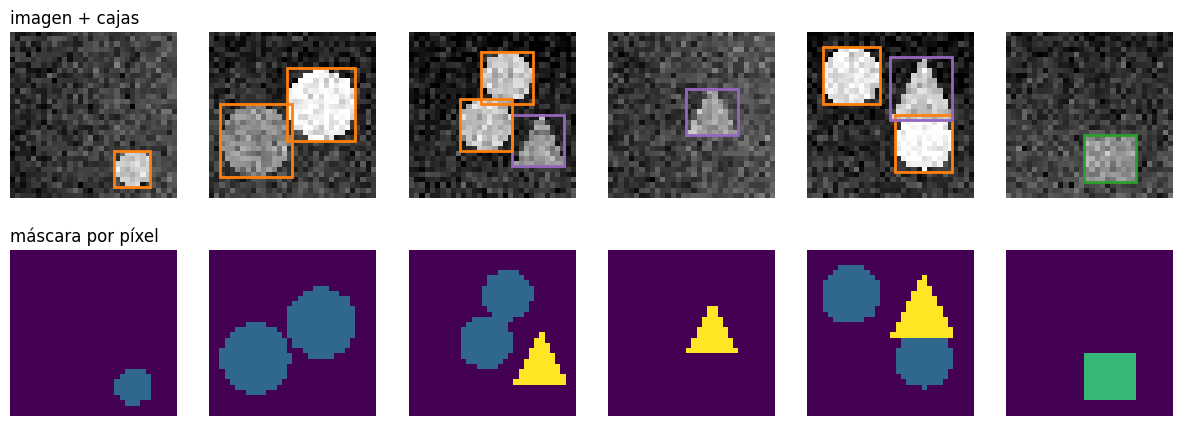

proporción de píxeles por clase: {'fondo': '85.5%', 'círculo': '5.7%', 'cuadrado': '5.1%', 'triángulo': '3.7%'}


In [2]:
S = 32
CLASSES = ["fondo", "círculo", "cuadrado", "triángulo"]
yy, xx = np.mgrid[0:S, 0:S] + 0.5

def shape_mask(kind, cx, cy, r):
    if kind == 1:
        return (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2
    if kind == 2:
        return (np.abs(xx - cx) <= r * 0.85) & (np.abs(yy - cy) <= r * 0.85)
    # triángulo hacia arriba inscrito en la caja [cx-r, cx+r] x [cy-r, cy+r]
    top, base = cy - r, cy + r
    half_width = r * (yy - top) / (2 * r)
    return (yy >= top) & (yy <= base) & (np.abs(xx - cx) <= half_width)

def make_scene(rng):
    img = rng.uniform(0.0, 0.25) + 0.15 * (xx / S if rng.random() < 0.5 else yy / S)     # iluminación desigual
    mask = np.zeros((S, S), dtype=np.int64)
    boxes = []
    for _ in range(rng.integers(1, 4)):
        for attempt in range(20):                                   # se evitan solapamientos grandes
            kind, r = int(rng.integers(1, 4)), rng.uniform(3.5, 7)
            cx, cy = rng.uniform(r, S - r), rng.uniform(r, S - r)
            m = shape_mask(kind, cx, cy, r)
            if (mask[m] > 0).mean() < 0.1:
                break
        img = np.where(m, rng.uniform(0.55, 1.0), img)
        mask[m] = kind
        ys, xs = np.where(m)
        boxes.append((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1, kind))
    img = img + rng.normal(0, 0.08, img.shape)
    return img.astype(np.float32), mask, boxes

def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    data = [make_scene(rng) for _ in range(n)]
    X = torch.tensor(np.stack([d[0] for d in data])).unsqueeze(1)
    M = torch.tensor(np.stack([d[1] for d in data]))
    return X, M, [d[2] for d in data]

X_tr, M_tr, B_tr = make_dataset(3000, 0)
X_te, M_te, B_te = make_dataset(500, 1)
colors = {1: "tab:orange", 2: "tab:green", 3: "tab:purple"}

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for k in range(6):
    axes[0, k].imshow(X_tr[k, 0], cmap="gray", vmin=0, vmax=1)
    for x0, y0, x1, y1, c in B_tr[k]:
        axes[0, k].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, color=colors[c], lw=2))
    axes[1, k].imshow(M_tr[k], cmap="viridis", vmin=0, vmax=3)
    axes[0, k].axis("off"); axes[1, k].axis("off")
axes[0, 0].set_title("imagen + cajas", loc="left"); axes[1, 0].set_title("máscara por píxel", loc="left")
plt.show()
print("proporción de píxeles por clase:", {c: f"{(M_tr == i).float().mean().item():.1%}" for i, c in enumerate(CLASSES)})

Fíjate en el desequilibrio entre clases: la mayoría de los píxeles son fondo. Un modelo que predijera "fondo" en todas partes ya tendría alrededor de un 80 % de "exactitud", y por eso la segmentación se evalúa por clase con la **IoU** (abajo), no con la exactitud por píxel.

## 2. Segmentación semántica con una pequeña U-Net

Un clasificador comprime la imagen hasta un solo vector. Un segmentador debe producir una salida **del mismo tamaño que la entrada**. La **U-Net** (Ronneberger et al., 2015) hace ambas cosas:

* un **codificador** (camino de contracción) de convoluciones y pooling construye *qué* hay en la imagen, con una resolución cada vez menor;
* un **decodificador** (camino de expansión) de convoluciones transpuestas vuelve a aumentar la resolución para decir *dónde*;
* las **conexiones de salto** copian las características de alta resolución del codificador directamente al decodificador a la misma escala, para poder recuperar el detalle fino que el pooling perdió.

```
32×32 ─conv─► e1 (16c) ───────────────── salto ───────────────► concat ─conv─► 32×32 × 4 clases
                │ pool                                             ▲ subir
               16×16 ─conv─► e2 (32c) ─────── salto ───► concat ─conv─┘
                               │ pool                      ▲ subir
                              8×8 ─conv─► cuello de botella (64c) ┘
```

Una **convolución transpuesta** (`ConvTranspose2d`, paso 2) es el opuesto aprendible del pooling: cada píxel de entrada "pinta" un parche de 2×2 de la salida con pesos aprendidos.

In [3]:
def double_conv(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, skips=True, n_classes=4):
        super().__init__()
        self.skips = skips
        self.e1, self.e2, self.mid = double_conv(1, 16), double_conv(16, 32), double_conv(32, 64)
        self.up2, self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2), nn.ConvTranspose2d(32, 16, 2, stride=2)
        k = 2 if skips else 1
        self.d2, self.d1 = double_conv(32 * k, 32), double_conv(16 * k, 16)
        self.out = nn.Conv2d(16, n_classes, 1)                 # conv. 1x1: un clasificador en cada píxel
    def forward(self, x):
        e1 = self.e1(x)                                        # 32x32
        e2 = self.e2(F.max_pool2d(e1, 2))                      # 16x16
        m = self.mid(F.max_pool2d(e2, 2))                      # 8x8
        u2 = self.up2(m)
        d2 = self.d2(torch.cat([u2, e2], 1) if self.skips else u2)
        u1 = self.up1(d2)
        d1 = self.d1(torch.cat([u1, e1], 1) if self.skips else u1)
        return self.out(d1)                                    # (lote, 4, 32, 32): puntuaciones de clase por píxel

def iou_per_class(pred, mask, n=4):
    return [((pred == c) & (mask == c)).sum().item() / max(1, ((pred == c) | (mask == c)).sum().item()) for c in range(n)]

def fit_seg(model, epochs=8, lr=3e-3, batch=32):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr))
        for i in range(0, len(X_tr), batch):
            b = perm[i:i + batch]
            loss = F.cross_entropy(model(X_tr[b]), M_tr[b])     # entropía cruzada promediada sobre todos los píxeles
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return model(X_te).argmax(1)

seg = {}
for name, skips in [("U-Net", True), ("sin conexiones de salto", False)]:
    torch.manual_seed(0)
    t0 = time.time()
    model = UNet(skips)
    pred = fit_seg(model)
    seg[name] = (model, pred)
    ious = iou_per_class(pred, M_te)
    print(f"{name:24s} parámetros {count_params(model):,}  ({time.time() - t0:.0f} s)\n   exactitud por píxel {(pred == M_te).float().mean().item():.1%}   "
          + "   ".join(f"IoU {c} {v:.2f}" for c, v in zip(CLASSES, ious)) + f"   IoU media (objetos) {np.mean(ious[1:]):.2f}")

U-Net                    parámetros 117,444  (125 s)
   exactitud por píxel 99.9%   IoU fondo 1.00   IoU círculo 0.98   IoU cuadrado 0.98   IoU triángulo 0.98   IoU media (objetos) 0.98


sin conexiones de salto  parámetros 105,924  (104 s)
   exactitud por píxel 99.5%   IoU fondo 1.00   IoU círculo 0.95   IoU cuadrado 0.98   IoU triángulo 0.97   IoU media (objetos) 0.96


La **intersección sobre la unión** (IoU) de una clase es $\frac{|\text{predicho} \cap \text{real}|}{|\text{predicho} \cup \text{real}|}$: 1 es perfecto y, a diferencia de la exactitud por píxel, el enorme fondo no puede inflarla.

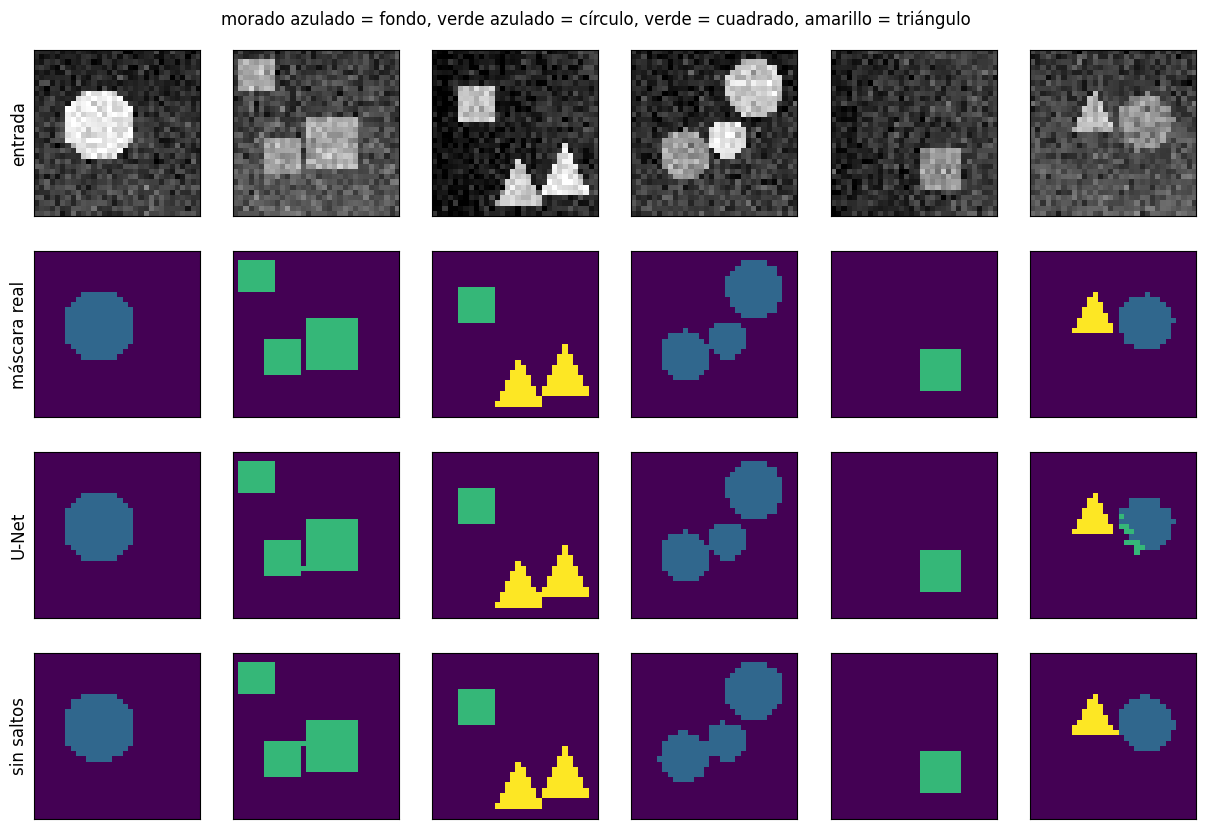

In [4]:
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for k in range(6):
    axes[0, k].imshow(X_te[k, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, k].imshow(M_te[k], cmap="viridis", vmin=0, vmax=3)
    axes[2, k].imshow(seg["U-Net"][1][k], cmap="viridis", vmin=0, vmax=3)
    axes[3, k].imshow(seg["sin conexiones de salto"][1][k], cmap="viridis", vmin=0, vmax=3)
for ax, t in zip(axes[:, 0], ["entrada", "máscara real", "U-Net", "sin saltos"]):
    ax.set_ylabel(t, fontsize=12)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("morado azulado = fondo, verde azulado = círculo, verde = cuadrado, amarillo = triángulo", y=0.92); plt.show()

Ambas redes funcionan bien con estas formas limpias; las conexiones de salto aportan un par de puntos de IoU, y la diferencia se concentra justo donde cabría esperar: en los bordes, las esquinas y las puntas de los triángulos, que el decodificador sin saltos tiene que reconstruir a partir de un resumen de 8×8. Con saltos, el decodificador sabe *qué* gracias al cuello de botella y *dónde* gracias a las características de alta resolución copiadas. En imágenes reales con estructura fina (vasos sanguíneos, bordes de carreteras) la diferencia es mucho mayor, y por eso la forma de U-Net se convirtió en estándar. La misma forma de codificador-decodificador con saltos se usa en imagen médica, en cartografía por satélite y como red de eliminación de ruido dentro de los modelos de difusión de imágenes.

## 3. Detección de objetos al estilo YOLO

La segmentación etiqueta píxeles, pero no separa dos objetos de la misma clase que se tocan ni los cuenta. La **detección** produce una caja por objeto.

La idea de **YOLO** ("You Only Look Once", solo miras una vez; Redmon et al., 2015) convierte la detección en un único problema de regresión. Se divide la imagen en una cuadrícula de $S \times S$ (aquí 4×4 celdas de 8×8 píxeles). La celda que contiene el **centro** de un objeto es la responsable de él, y predice:

| Salida | Significado | Pérdida |
|---|---|---|
| $p_{obj}$ | ¿hay un objeto centrado en esta celda? | entropía cruzada binaria, todas las celdas |
| $t_x, t_y$ | posición del centro dentro de la celda (0-1) | error cuadrático, solo celdas responsables |
| $t_w, t_h$ | anchura y altura de la caja respecto a la imagen | error cuadrático sobre $\sqrt{\cdot}$, solo celdas responsables |
| puntuaciones de clase | círculo / cuadrado / triángulo | entropía cruzada, solo celdas responsables |

Así que toda la red es una CNN cuya salida es un tensor de $4 \times 4 \times 8$. (El YOLO real añade varias cajas "ancla" por celda para que una celda pueda contener más de un objeto; nosotros nos quedamos con una.)

In [5]:
G, CELL = 4, S // 4

def encode_targets(boxes_list):
    T = torch.zeros(len(boxes_list), G, G, 6)                  # obj, tx, ty, tw, th, clase
    for n, boxes in enumerate(boxes_list):
        for x0, y0, x1, y1, c in boxes:
            cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
            gx, gy = min(int(cx // CELL), G - 1), min(int(cy // CELL), G - 1)
            T[n, gy, gx] = torch.tensor([1, cx / CELL - gx, cy / CELL - gy, (x1 - x0) / S, (y1 - y0) / S, c - 1])
    return T

T_tr, T_te = encode_targets(B_tr), encode_targets(B_te)
print(f"celdas con más de un centro de objeto (no se pueden representar, así que se ignoran): "
      f"{sum(len(b) for b in B_tr) - int(T_tr[..., 0].sum())} de {sum(len(b) for b in B_tr)} objetos de entrenamiento")

class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(double_conv(1, 16), nn.MaxPool2d(2), double_conv(16, 32), nn.MaxPool2d(2),
                                  double_conv(32, 64), nn.MaxPool2d(2), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU())
        self.head = nn.Conv2d(64, 1 + 4 + 3, 1)                # un vector de predicción por celda de la cuadrícula
    def forward(self, x):
        return self.head(self.body(x)).permute(0, 2, 3, 1)     # (lote, 4, 4, 8)

def yolo_loss(out, T):
    obj = T[..., 0] > 0
    l_obj = F.binary_cross_entropy_with_logits(out[..., 0], T[..., 0])
    xy = torch.sigmoid(out[..., 1:3][obj]); wh = torch.sigmoid(out[..., 3:5][obj])
    l_box = F.mse_loss(xy, T[..., 1:3][obj]) + F.mse_loss(wh.sqrt(), T[..., 3:5][obj].sqrt())
    l_cls = F.cross_entropy(out[..., 5:][obj], T[..., 5][obj].long())
    return l_obj + 5 * l_box + l_cls

torch.manual_seed(0)
det = Detector()
opt = torch.optim.Adam(det.parameters(), lr=2e-3)
t0 = time.time()
for ep in range(15):
    det.train()
    perm = torch.randperm(len(X_tr))
    for i in range(0, len(X_tr), 32):
        b = perm[i:i + 32]
        loss = yolo_loss(det(X_tr[b]), T_tr[b])
        opt.zero_grad(); loss.backward(); opt.step()
print(f"detector: {count_params(det):,} parámetros, entrenado en {time.time() - t0:.0f} s, pérdida final {loss.item():.3f}")

celdas con más de un centro de objeto (no se pueden representar, así que se ignoran): 31 de 6002 objetos de entrenamiento


detector: 109,688 parámetros, entrenado en 99 s, pérdida final 0.005


### De las salidas de la cuadrícula a las cajas: umbral y supresión de no máximos

La decodificación convierte cada celda segura de nuevo en una caja en coordenadas de píxel. A veces dos celdas vecinas reclaman el mismo objeto, así que el último paso es la **supresión de no máximos (NMS)**: ordenar las cajas por confianza, quedarse con la mejor, borrar todas las cajas restantes de la misma clase que se solapen con ella más de un umbral de IoU, y repetir.

Una caja predicha cuenta como **verdadero positivo** si se solapa con una caja de referencia aún no emparejada de la misma clase con IoU ≥ 0,5.

In [6]:
def box_iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)

def decode(out, threshold=0.5, nms_iou=0.4):
    boxes = []
    p = torch.sigmoid(out[..., 0])
    for gy in range(G):
        for gx in range(G):
            if p[gy, gx] > threshold:
                tx, ty = torch.sigmoid(out[gy, gx, 1:3]).tolist(); tw, th = torch.sigmoid(out[gy, gx, 3:5]).tolist()
                cx, cy, w, h = (gx + tx) * CELL, (gy + ty) * CELL, tw * S, th * S
                boxes.append((cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2, int(out[gy, gx, 5:].argmax()) + 1, p[gy, gx].item()))
    boxes.sort(key=lambda b: -b[5])
    kept = []
    for b in boxes:                                            # supresión de no máximos
        if all(k[4] != b[4] or box_iou(k, b) < nms_iou for k in kept):
            kept.append(b)
    return kept

def evaluate(threshold):
    tp = fp = 0
    n_true = sum(len(b) for b in B_te)
    det.eval()
    with torch.no_grad():
        outs = det(X_te)
    for out, truth in zip(outs, B_te):
        unmatched = list(truth)
        for b in decode(out, threshold):
            match = next((t for t in unmatched if t[4] == b[4] and box_iou(t, b) >= 0.5), None)
            if match: tp += 1; unmatched.remove(match)
            else: fp += 1
    return tp / max(1, tp + fp), tp / n_true

print(f"{'umbral':>9s} {'precisión':>10s} {'exhaust.':>8s}")
pr = []
for th in [0.9, 0.7, 0.5, 0.3, 0.1]:
    p, r = evaluate(th); pr.append((r, p))
    print(f"{th:9.1f} {p:10.1%} {r:8.1%}")

   umbral  precisión exhaust.


      0.9      98.8%    93.9%


      0.7      98.9%    95.0%


      0.5      98.9%    96.0%


      0.3      98.9%    96.8%


      0.1      98.9%    97.4%


La **precisión** es la proporción de cajas predichas que son correctas; la **exhaustividad** (recall) es la proporción de objetos reales que se encontraron. El umbral de confianza intercambia una por otra, y los bancos de pruebas de detección resumen toda la curva como *precisión media promedio* (mAP). Veamos algunas detecciones:

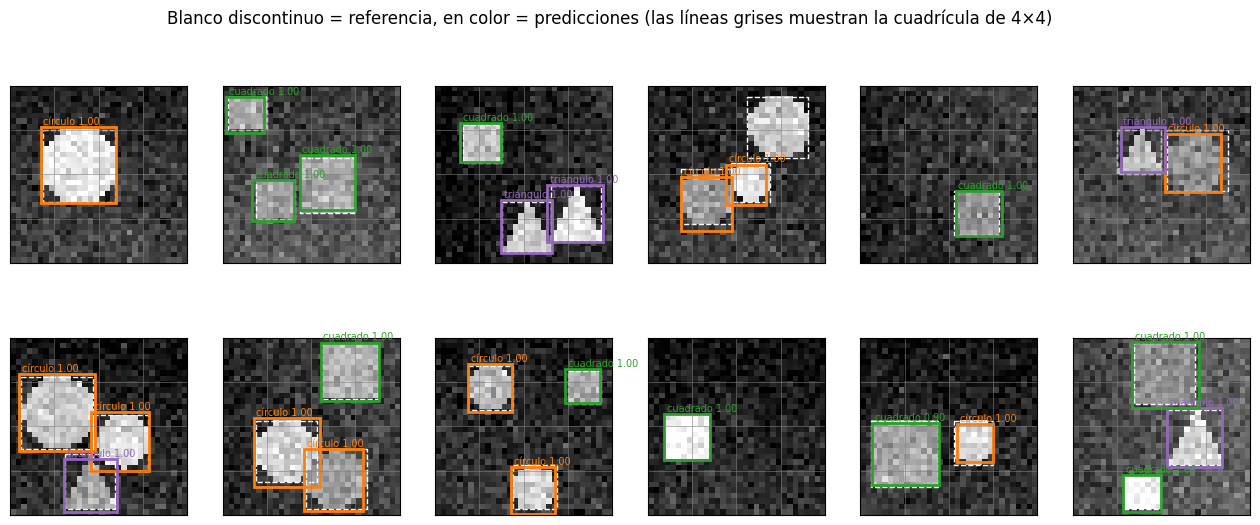

In [7]:
det.eval()
with torch.no_grad():
    outs = det(X_te[:12])
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, img, out, truth in zip(axes.ravel(), X_te[:12], outs, B_te[:12]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    for x0, y0, x1, y1, c in truth:
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, color="white", lw=1, ls="--"))
    for x0, y0, x1, y1, c, conf in decode(out):
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, color=colors[c], lw=2))
        ax.text(x0, y0 - 1, f"{CLASSES[c]} {conf:.2f}", color=colors[c], fontsize=7)
    for k in range(1, G):
        ax.axhline(k * CELL - 0.5, color="gray", lw=0.4); ax.axvline(k * CELL - 0.5, color="gray", lw=0.4)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Blanco discontinuo = referencia, en color = predicciones (las líneas grises muestran la cuadrícula de 4×4)"); plt.show()

Una sola evaluación de la red por imagen da todas las cajas a la vez, y por eso los detectores al estilo YOLO funcionan en tiempo real. Su debilidad clásica se ve en el paso de codificación: una celda solo puede contener un objeto, así que los objetos pequeños muy juntos son difíciles. Los detectores modernos usan varias cajas ancla por celda, varias resoluciones de cuadrícula y (en los modelos tipo DETR) atención en lugar de una cuadrícula.

## 4. Aprendizaje métrico: aprender qué significa "lo mismo"

Un clasificador solo puede producir las clases con las que se entrenó. El reconocimiento facial no puede funcionar así: un teléfono debe reconocer a su dueño a partir de una sola foto de registro, sin volver a entrenar. La solución (FaceNet, Schroff et al., 2015; y antes las redes siamesas) es aprender un **embedding** $f(x)$ en el que las imágenes de la misma identidad estén cerca y las de identidades distintas, lejos. Entonces:

* **verificación**: es la misma persona si $\|f(x_1) - f(x_2)\| < \tau$;
* **reconocimiento**: el embedding registrado más cercano.

La **pérdida triplete** entrena esto directamente. Se toma un *ancla* $a$, un *positivo* $p$ (misma identidad) y un *negativo* $n$ (identidad distinta):

$$ \mathcal{L} = \max\big(0,\; \|f(a) - f(p)\|^2 - \|f(a) - f(n)\|^2 + \alpha\big) $$

Es cero en cuanto el negativo está más lejos que el positivo por al menos el margen $\alpha$.

Usamos dígitos manuscritos como "identidades" de sustitución. La red se entrena **solo con los dígitos del 0 al 6**. Después la probamos con imágenes nuevas de esos dígitos y con el **7, el 8 y el 9**, que nunca ha visto: la posición en la que está un sistema facial cuando conoce a una persona nueva.

In [8]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)
yd = torch.tensor(digits.target)
seen, unseen = yd <= 6, yd >= 7
g_split = torch.Generator().manual_seed(0)
perm = torch.randperm(int(seen.sum()), generator=g_split)
Xseen, yseen = Xd[seen][perm], yd[seen][perm]
Xs, ys = Xseen[:900], yseen[:900]                 # imágenes de entrenamiento de los dígitos 0-6
Xh, yh = Xseen[900:], yseen[900:]                 # imágenes reservadas de los MISMOS dígitos
Xu, yu = Xd[unseen], yd[unseen]                   # dígitos 7-9, nunca vistos en el entrenamiento

class Embedder(nn.Module):
    def __init__(self, dim=16):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
                                 nn.MaxPool2d(2), nn.Flatten(), nn.Linear(64 * 16, 128), nn.ReLU(), nn.Linear(128, dim))
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)                  # los embeddings viven en la esfera unidad

def pk_batch(X, y, classes, P=7, K=8, gen=None):
    # P identidades x K imágenes cada una, para que cada ancla tenga positivos y negativos en el mismo lote
    idx = []
    for c in classes[torch.randperm(len(classes), generator=gen)[:P]]:
        pool = (y == c).nonzero().ravel()
        idx.append(pool[torch.randint(0, len(pool), (K,), generator=gen)])
    idx = torch.cat(idx)
    return X[idx], y[idx]

def batch_hard_triplet_loss(f, y, margin):
    # para cada ancla: su positivo MÁS LEJANO y su negativo MÁS CERCANO del lote (el triplete más difícil)
    D = torch.cdist(f, f).pow(2)
    same = y[:, None] == y[None, :]
    hardest_pos = (D * same).max(1).values
    hardest_neg = (D + same * 1e9).min(1).values
    return F.relu(hardest_pos - hardest_neg + margin).mean()

torch.manual_seed(0)
emb_net = Embedder()
opt = torch.optim.Adam(emb_net.parameters(), lr=1e-3)
gen = torch.Generator().manual_seed(0)
classes, t0 = torch.arange(7), time.time()
for step in range(1500):
    xb, yb = pk_batch(Xs, ys, classes, gen=gen)
    loss = batch_hard_triplet_loss(emb_net(xb), yb, margin=0.2)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"entrenado con los dígitos 0-6 durante 1500 lotes en {time.time() - t0:.0f} s, pérdida final {loss.item():.3f}")

entrenado con los dígitos 0-6 durante 1500 lotes en 29 s, pérdida final 0.000


Los tripletes aleatorios son casi siempre *fáciles* (un "1" y un "0" ya están lejos), así que enseguida dejan de enseñar nada. La **minería de lo más difícil del lote** (batch-hard mining; Hermans et al., 2017) construye cada lote con unas pocas identidades con varias imágenes cada una y, para cada ancla, usa solo su positivo más difícil y su negativo más difícil dentro del lote.

Ahora la prueba, en el escenario de un sistema de reconocimiento facial: **registrar una imagen por identidad** y después reconocer cada una de las demás imágenes por su embedding registrado más cercano. La ejecutamos dos veces: con imágenes nuevas de los dígitos vistos en el entrenamiento (0-6) y con los dígitos que la red nunca ha visto (7-9). Los píxeles en bruto son la referencia.

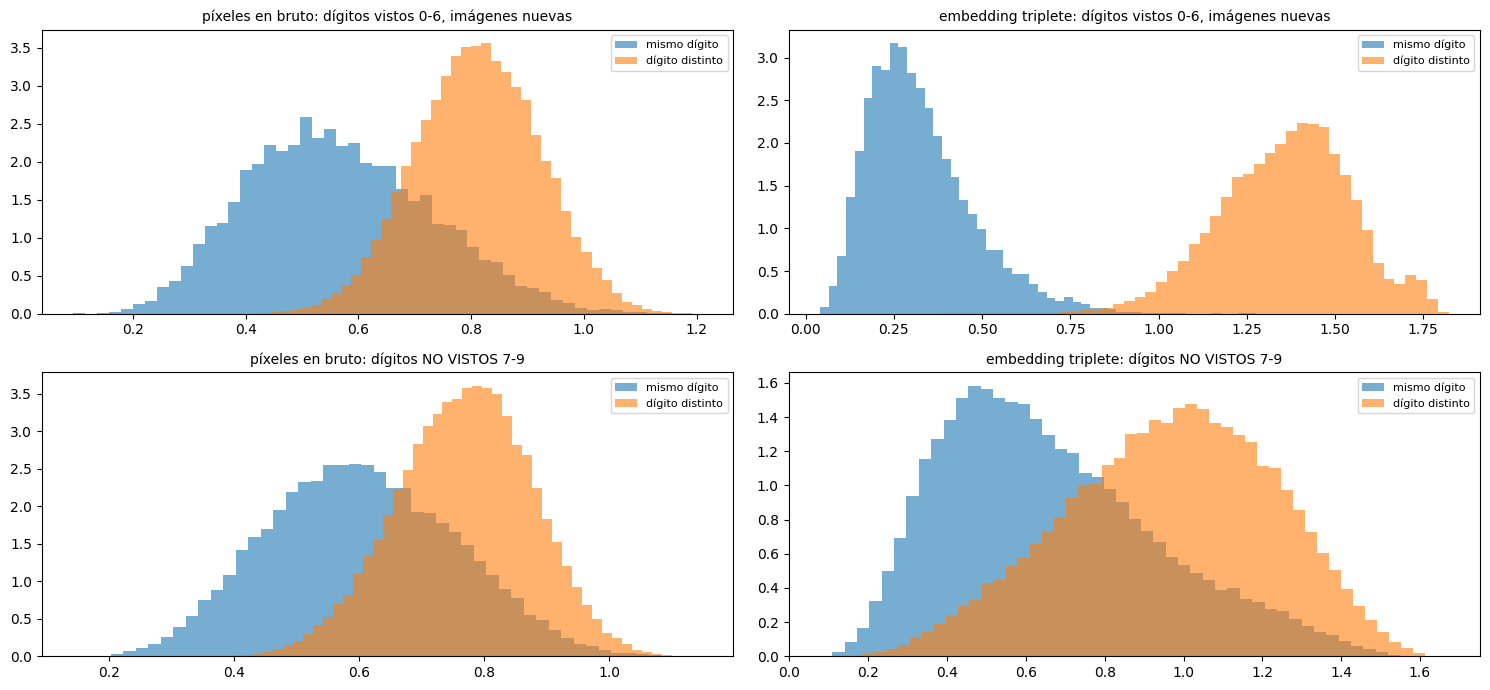

reconocimiento con UNA sola imagen de registro por identidad
                        vistos 0-6 (7 clases)  no vistos 7-9 (3 clases)
azar                                    14.3%                     33.3%


píxeles en bruto                        74.0%                     73.5%


embedding triplete                      99.2%                     68.2%


In [9]:
emb_net.eval()
with torch.no_grad():
    Eh, Eu = emb_net(Xh), emb_net(Xu)
pix = lambda X: F.normalize(X.flatten(1), dim=1)

def pair_distances(E, y):
    D = torch.cdist(E, E)
    same = (y[:, None] == y[None, :]) & ~torch.eye(len(y), dtype=torch.bool)
    diff = y[:, None] != y[None, :]
    return D[same].numpy(), D[diff].numpy()

def one_shot(E, y, trials=200, seed=0):
    # registra UN ejemplo aleatorio por identidad y clasifica cada uno de los demás por el embedding registrado más cercano
    g = np.random.default_rng(seed); ids = sorted(set(y.tolist())); acc = []
    for _ in range(trials):
        refs = [g.choice(np.where(y.numpy() == d)[0]) for d in ids]
        pred = torch.tensor(ids)[torch.cdist(E, E[refs]).argmin(1)]
        mask = torch.ones(len(y), dtype=torch.bool); mask[refs] = False
        acc.append((pred[mask] == y[mask]).float().mean().item())
    return np.mean(acc)

fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for row, (label, X, y, E) in enumerate([("dígitos vistos 0-6, imágenes nuevas", Xh, yh, Eh), ("dígitos NO VISTOS 7-9", Xu, yu, Eu)]):
    for col, (name, Z) in enumerate([("píxeles en bruto", pix(X)), ("embedding triplete", E)]):
        s, d = pair_distances(Z, y)
        ax = axes[row, col]
        ax.hist(s, bins=50, alpha=0.6, density=True, label="mismo dígito"); ax.hist(d, bins=50, alpha=0.6, density=True, label="dígito distinto")
        ax.set_title(f"{name}: {label}", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("reconocimiento con UNA sola imagen de registro por identidad")
print(f"{'':22s} {'vistos 0-6 (7 clases)':>22s} {'no vistos 7-9 (3 clases)':>25s}")
print(f"{'azar':22s} {1/7:22.1%} {1/3:25.1%}")
print(f"{'píxeles en bruto':22s} {one_shot(pix(Xh), yh):22.1%} {one_shot(pix(Xu), yu):25.1%}")
print(f"{'embedding triplete':22s} {one_shot(Eh, yh):22.1%} {one_shot(Eu, yu):25.1%}")

Con las identidades con las que se entrenó, el embedding es muchísimo mejor que los píxeles en bruto: las distancias "iguales" y "distintas" se separan limpiamente, y una imagen de registro basta. Con los dígitos no vistos el panorama es mucho menos halagador. Según la semilla aleatoria, el embedding queda en torno a la referencia de píxeles en bruto, a veces un poco por encima y a veces por debajo (prueba con varias semillas).

Es un resultado honesto e importante, no un fallo. **Siete identidades de entrenamiento no bastan para aprender una noción general de "lo mismo".** Con tan pocas, la red aprende características que separan *esos siete dígitos* y no tiene ningún motivo para organizar bien el resto del espacio. FaceNet se entrenó con unos 8 millones de identidades precisamente por esto: generalizar a identidades nuevas es una propiedad que se compra con *diversidad de identidades*, no con más imágenes de las mismas pocas. La misma lección vale para cualquier modelo de embeddings, incluidos los embeddings de texto que hay detrás de la generación aumentada por recuperación (RAG): funcionan con entradas nuevas porque se entrenaron con una variedad enorme de ellas.

## Ideas clave

* **Segmentación** = un clasificador en cada píxel. Las redes codificador-decodificador con **conexiones de salto** (U-Net) recuperan el detalle que el pooling descarta. Se evalúa con la **IoU** por clase, no con la exactitud por píxel.
* La **detección** puede plantearse como una sola regresión sobre una cuadrícula (YOLO): presencia de objeto + caja + clase por celda, decodificadas con un umbral y **supresión de no máximos**. La precisión y la exhaustividad se intercambian a través del umbral de confianza.
* El **aprendizaje métrico** con una pérdida triplete aprende un embedding donde la distancia significa similitud, la base de la verificación facial y de la búsqueda por similitud. Generalizar a identidades nunca vistas en el entrenamiento requiere entrenar con *muchas* identidades.

## Ejercicios

1. Entrena la U-Net durante 2 épocas en lugar de 8. ¿Qué clase sufre más y por qué podrían ser los triángulos los más difíciles?
2. Añade una cuarta forma (por ejemplo un anillo: un círculo con un agujero) a `shape_mask` y vuelve a entrenar el segmentador y el detector.
3. En el detector, cambia la cuadrícula a 8×8 celdas de 4 píxeles. ¿Cómo cambian la precisión y la exhaustividad, y por qué las cuadrículas finas ayudan en escenas abarrotadas?
4. Quita la NMS de `decode` (conserva todas las cajas por encima del umbral). ¿Cómo cambia la precisión?
5. Entrena la red triplete con márgenes de 0,1 y 0,5, y con tres semillas aleatorias para cada uno. ¿Qué tan estable es la exactitud con un solo ejemplo en los dígitos no vistos, comparada con los vistos?
6. Entrena solo con los dígitos 0-4 y prueba con 5-9, y después entrena con 0-7 y prueba con 8-9. ¿Mejora la exactitud con identidades no vistas a medida que crece el número de identidades de entrenamiento?